### Evaluate


--- Final Classification Report ---
              precision    recall  f1-score   support

     Class 0     0.8738    0.9112    0.8921      8288
     Class 1     0.5900    0.5397    0.5638      2994
     Class 2     0.6050    0.5801    0.5923      1529
     Class 3     0.4673    0.4043    0.4336       230
     Class 4     0.6092    0.5699    0.5889        93

    accuracy                         0.7767     13134
   macro avg     0.6291    0.6011    0.6141     13134
weighted avg     0.7688    0.7767    0.7722     13134



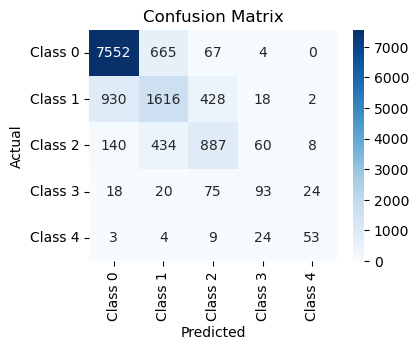

In [20]:

def final_evaluate(model, test_loader, device, class_names):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

    # 1. Show Classification Metrics
    print("\n--- Final Classification Report ---")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

    
    f1_macro = f1_score(all_labels, all_preds, average="macro", zero_division=0)
    acc = accuracy_score(all_labels, all_preds)
    results = np.array([f1_macro, acc])

    # 2. Compute Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    
    # 3. Plot Confusion Matrix
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()
    
    return results

# ============================================================
# ============================================================
# Usage Example:
names = ['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4']
Deep_results = final_evaluate(model, test_loader, device, names)
# ============================================================
# ============================================================
